<a href="https://colab.research.google.com/github/pari-plan/Student_Marks_Prediction_ML.ipynb/blob/main/Cat_Dog_CNN_Classification_ipynb_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import os
import shutil
import zipfile
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from PIL import Image
from tensorflow import keras
from tensorflow.keras import layers
from google.colab import files

print("TensorFlow version:", tf.__version__)
print("GPU available:", len(tf.config.list_physical_devices("GPU")) > 0)


TensorFlow version: 2.21.0
GPU available: False


In [ ]:

dataset_url = (
    "https://download.microsoft.com/download/3/E/1/"
    "3E1C3F21-ECDB-4869-8368-6DEBA77B919F/"
    "kagglecatsanddogs_5340.zip"
)

zip_path = "/content/cats_dogs.zip"

if not os.path.exists(zip_path):
    tf.keras.utils.get_file(
        fname="cats_dogs.zip",
        origin=dataset_url,
        cache_dir="/content",
        cache_subdir="."
    )
    # get_file saves the file in the cache directory
    if not os.path.exists(zip_path):
        possible_path = "/content/cats_dogs.zip"
        if os.path.exists(possible_path):
            zip_path = possible_path

print("Dataset download step completed.")


824887076/824887076 ━━━━━━━━━━━━━━━━━━━━ 7s 0us/step
Dataset download step completed.


In [ ]:
extract_path = "/content/cat_dog_raw"

if not os.path.exists(extract_path):
    os.makedirs(extract_path, exist_ok=True)
    with zipfile.ZipFile("/content/cats_dogs.zip", "r") as z:
        z.extractall(extract_path)

print("Dataset extracted.")
print(os.listdir(extract_path)[:10])

Dataset extracted.
['CDLA-Permissive-2.0.pdf', 'readme[1].txt', 'PetImages']


In [ ]:
raw_root = "/content/cat_dog_raw/PetImages"
small_root = "/content/cat_dog_dataset"

os.makedirs(small_root, exist_ok=True)

random.seed(42)
limit_per_class = 800

for class_name in ["Cat", "Dog"]:
    source_folder = os.path.join(raw_root, class_name)
    target_folder = os.path.join(small_root, class_name)
    os.makedirs(target_folder, exist_ok=True)

    valid_files = []

    for filename in os.listdir(source_folder):
        path = os.path.join(source_folder, filename)

        if not filename.lower().endswith((".jpg", ".jpeg", ".png")):
            continue

        try:
            with Image.open(path) as img:
                img.verify()
            valid_files.append(path)
        except Exception:
            pass

    random.shuffle(valid_files)
    copied = 0

    for source_path in valid_files:
        if copied >= limit_per_class:
            break

        try:
            with Image.open(source_path) as img:
                img.convert("RGB").save(
                    os.path.join(target_folder, f"{class_name.lower()}_{copied}.jpg"),
                    "JPEG"
                )
            copied += 1
        except Exception:
            pass

    print(f"{class_name}: {copied} valid images copied")

print("Prepared dataset:", small_root)


Cat: 800 valid images copied


/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Dog: 800 valid images copied
Prepared dataset: /content/cat_dog_dataset


In [ ]:
IMG_SIZE = (128, 128)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    small_root,
    validation_split=0.20,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    small_root,
    validation_split=0.20,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

class_names = train_ds.class_names
print("Class order:", class_names)


Found 1600 files belonging to 2 classes.
Using 1280 files for training.
Found 1600 files belonging to 2 classes.
Using 320 files for validation.
Class order: ['Cat', 'Dog']


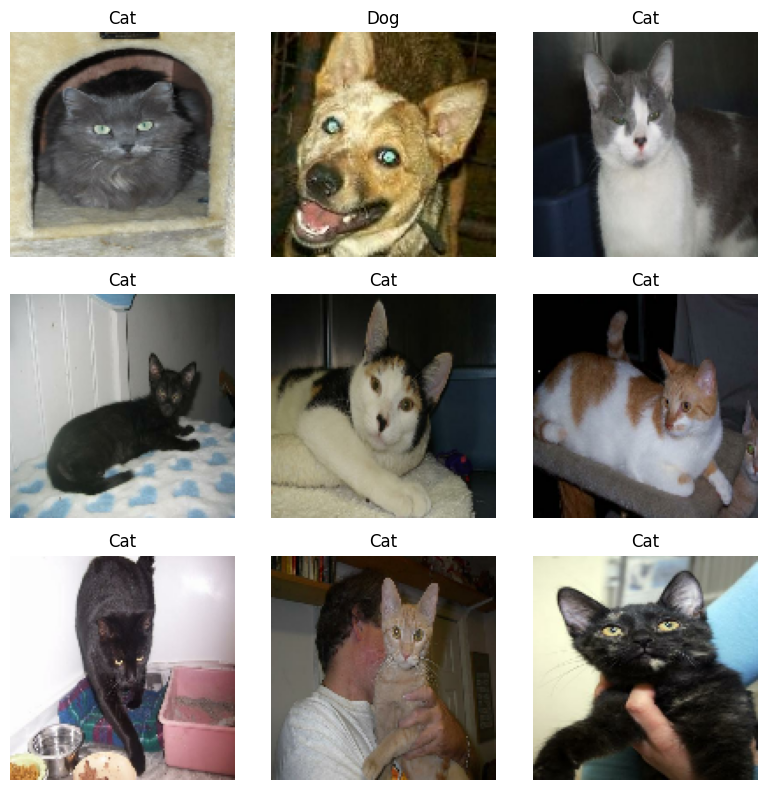

In [ ]:
plt.figure(figsize=(8, 8))

for images, labels in train_ds.take(1):
    for i in range(min(9, len(images))):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i][0])])
        plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:
model = keras.Sequential([
    keras.Input(shape=(128, 128, 3)),

    # Scale pixel values from 0–255 to 0–1
    layers.Rescaling(1.0 / 255),

    # First convolution block
    layers.Conv2D(16, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Second convolution block
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Third convolution block
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Classification layers
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       802,880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 826,529 (3.15 MB)

 Trainable params: 826,529 (3.15 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=[early_stop]
)


Epoch 1/5
40/40 ━━━━━━━━━━━━━━━━━━━━ 26s 599ms/step - accuracy: 0.5164 - loss: 0.6961 - val_accuracy: 0.5875 - val_loss: 0.6839
Epoch 2/5
40/40 ━━━━━━━━━━━━━━━━━━━━ 24s 584ms/step - accuracy: 0.5781 - loss: 0.6738 - val_accuracy: 0.5969 - val_loss: 0.6472
Epoch 3/5
40/40 ━━━━━━━━━━━━━━━━━━━━ 40s 559ms/step - accuracy: 0.6359 - loss: 0.6419 - val_accuracy: 0.6531 - val_loss: 0.6350
Epoch 4/5
40/40 ━━━━━━━━━━━━━━━━━━━━ 24s 610ms/step - accuracy: 0.6664 - loss: 0.6082 - val_accuracy: 0.6344 - val_loss: 0.6650
Epoch 5/5
40/40 ━━━━━━━━━━━━━━━━━━━━ 23s 577ms/step - accuracy: 0.7180 - loss: 0.5551 - val_accuracy: 0.6812 - val_loss: 0.6257


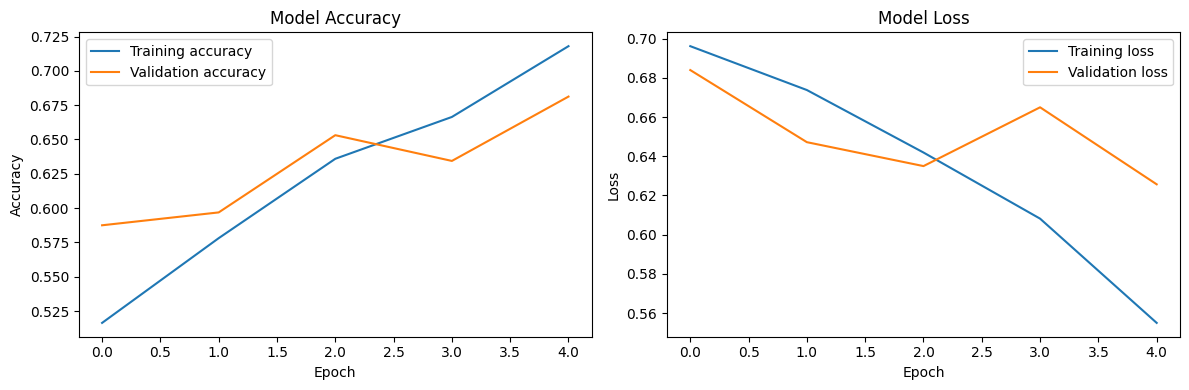

In [ ]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


In [ ]:
val_loss, val_accuracy = model.evaluate(val_ds, verbose=1)

print(f"Validation loss: {val_loss:.4f}")
print(f"Validation accuracy: {val_accuracy * 100:.2f}%")


10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 146ms/step - accuracy: 0.6812 - loss: 0.6257
Validation loss: 0.6257
Validation accuracy: 68.12%


Saving _.jpeg to _.jpeg


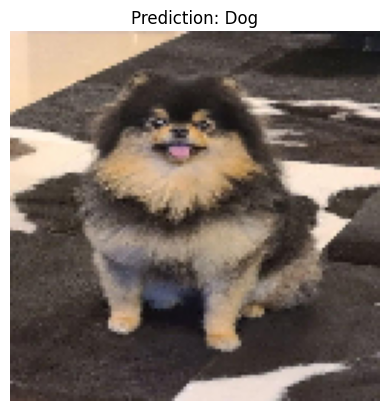

Predicted class: Dog
Model score for Dog: 0.5968
Confidence for predicted class: 59.68%


In [16]:
uploaded = files.upload()

for filename in uploaded.keys():
    img = keras.utils.load_img(
        filename,
        target_size=IMG_SIZE
    )

    img_array = keras.utils.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)

    score = float(model.predict(img_array, verbose=0)[0][0])

    # The model's sigmoid score corresponds to class index 1.
    predicted_index = 1 if score >= 0.5 else 0
    predicted_class = class_names[predicted_index]
    confidence = score if predicted_index == 1 else 1 - score

    plt.imshow(img)
    plt.axis("off")
    plt.title(f"Prediction: {predicted_class}")
    plt.show()

    print("Predicted class:", predicted_class)
    print(f"Model score for {class_names[1]}: {score:.4f}")
    print(f"Confidence for predicted class: {confidence * 100:.2f}%")

In [17]:
model.save("/content/cat_dog_cnn.keras")
print("Model saved successfully.")

Model saved successfully.
